In [2]:
import numpy as np
from scipy.io import loadmat
import os
import pickle
import torch
import torch.nn as nn
import numpy as np
import time
import sys
import os
import pandas as pd
from datetime import datetime

project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.append(project_root)

from sklearn.model_selection import train_test_split
from utils.dataset_loader import load_data
from utils.feature_extraction import  calculate_psd, calculate_de
from utils.preprocessing import apply_bandpass_filter, baseline_correction, apply_normalization, apply_pca
from utils.tools import (freeUpMemories, get_optimizer, load_loading_config, load_training_config)

In [ ]:
processed_dir = r"C:\FACED dataset\Processed_data"
label_dir = r"C:\FACED dataset\Data"
save_dir = r"C:\FACED dataset\Preprocessed_data"

def load_full_labels(mat_path):
    mat = loadmat(mat_path)
    after_remark = mat['After_remark']
    raw_scores = after_remark['score'].squeeze()
    raw_vids = after_remark['vid'].squeeze()
    scores = np.array([s.squeeze() for s in raw_scores])        # (28, 12)
    vids = np.array([v.squeeze() for v in raw_vids])            # (28,)
    sorted_idx = np.argsort(vids)
    labels = np.argmax(scores[sorted_idx, :8], axis=1)
    return sorted_idx, labels, scores[sorted_idx]

def load_eeg_data(pkl_path):
    with open(pkl_path, 'rb') as f:
        eeg_data = pickle.load(f)
    return eeg_data

def get_subject_list(processed_dir, selected_subjects=None):
    subjects = sorted([f for f in os.listdir(processed_dir) if f.endswith(".pkl")])
    if selected_subjects:
        subjects = [s for s in subjects if s.split(".")[0] in selected_subjects]
    return subjects

def segment_reshape_eeg_data(eeg_data, sorted_idx, labels, scores, window_size=250, stride=250):
    X_all = []
    y_all = []
    scores_all = []
    eeg_sorted = eeg_data[sorted_idx]  # (28, 32, 7500)
    for trial, label, score in zip(eeg_sorted, labels, scores):
        trial = trial[:, :7500] 
        T = trial.shape[1]
        
        for start in range(0, T - window_size + 1, stride):
            seg = trial[:, start:start + window_size]  # shape: (32, window)
            seg = seg.T  # (window, 32)
            X_all.append(seg)
            y_all.append(label)
            scores_all.append(score)
            
    return X_all, y_all, scores_all

def segment_reshape(labels, scores, window_size=250, stride=250):
    y_all = []
    scores_all = []
    for label, score in zip(labels, scores):
        for start in range(0, 7500 - window_size + 1, stride):
            y_all.append(label)
            scores_all.append(score)
            
    return y_all, scores_all

def load_full_processed_data(processed_dir, label_dir, window_size=250, stride=250, selected_subjects=None):
    y_all = []
    scores_all = []

    subjects = get_subject_list(processed_dir, selected_subjects)

    for sub_file in subjects:
        sub_id = sub_file.split(".")[0]  # sub000
        mat_path = os.path.join(label_dir, sub_id, 'After_remarks.mat')

        sorted_idx, labels, scores = load_full_labels(mat_path)
        y, scores = segment_reshape(labels, scores, window_size,stride)
        y_all.extend(y)
        scores_all.extend(scores)

    return np.array(y_all).astype(np.float32),  np.array(scores_all).astype(np.float32)

In [5]:
load_config_id = 8
training_config_id = 3

# Loading Config
config = load_loading_config(load_config_id)
load_method = config['load_method']
window_size = config['window_size']
stride = config['stride']
use_pca = config['use_pca']
use_psd = config['use_psd']
psd_bands = config['psd_bands']
use_psd_pca = config['use_psd_pca']
use_de = config['use_de']
de_bands = config['de_bands']
use_de_pca = config['use_de_pca']
apply_filter = config['apply_filter']
lowcut: float = config['lowcut']
highcut: float = config['highcut']
fs_value: int = config['fs_value']
filter_order = config['filter_order']
apply_baseline = config['apply_baseline']
baseline_window = config['baseline_window']
normalize = config['normalize']
normalization_method = config['normalization_method']

# Training Config
training_config = load_training_config(training_config_id)
random_seed = training_config['random_seed']
np.random.seed(random_seed)
torch.manual_seed(random_seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device :",device)
if device.type == "cuda": torch.cuda.set_per_process_memory_fraction(0.9)
apply_train_test_split = training_config['apply_train_test_split']
test_size = training_config['test_size']
epochs = training_config['epochs']
batch_size = training_config['batch_size']
num_classes = training_config['num_classes']
sigmoid_threshold = training_config['sigmoid_threshold']

# Optimizer Config
optimizer_type = training_config['optimizer_type']
learning_rate = training_config['learning_rate']
learning_rate_to_save = training_config['learning_rate_to_save']
weight_decay = training_config['weight_decay']
momentum = training_config['momentum']
betas = training_config['betas']

# Model config
model_name = "1D_CNN_Residual_Blocks"
kernel_size: int = 7
dropout= 0.3

device : cuda


In [7]:
apply_train_test_split = False
X_all, y_all = load_data(load_method,window_size,stride,apply_filter, lowcut,
	highcut, fs_value, filter_order,apply_baseline,baseline_window, normalize, normalization_method,
	apply_train_test_split,test_size,random_seed,batch_size,True,None,None,num_classes,use_psd,psd_bands,
	use_psd_pca,use_de,de_bands,use_de_pca,use_pca,None)

full_path : C:\FACED dataset\Preprocessed_data\pre_XY_win500_str500_low1_high50_fs250_order4_base20_norm_zscore_psd[2, 3]pca_de[1, 2, 3, 4]pca_pca.pkl
file exists , loading ...
Existing Data Shape: (51660, 500, 112) (51660,)
start to binarize labels
y_all classes :  [0 1] Class counts: [27900 23760]
Final Data Shape: (51660, 500, 112) (51660,)
returned X_all, y_all


In [17]:
y_all, scores_all = load_full_processed_data(processed_dir,label_dir,window_size,stride, None)

In [18]:
print("Proccesed Data Shape:", X_all.shape, y_all.shape, scores_all.shape)

Proccesed Data Shape: (51660, 500, 112) (51660,) (51660, 12)


In [21]:
X_train, X_test, scores_train, scores_test = train_test_split(
	X_all, scores_all, test_size=test_size, stratify=scores_all, random_state=random_seed)

In [22]:
X_all_test = X_test
y_all = np.argmax(scores_test[:,:8],axis=1)

In [19]:
X_all[5166][250][80]

-0.035692062

In [20]:
scores_all[5166]

array([2.0289917 , 0.3627889 , 0.67416584, 0.40010172, 0.4459025 ,
       6.1316366 , 2.1839967 , 1.3900025 , 3.6980712 , 0.8751139 ,
       0.03312581, 0.30394286], dtype=float32)

In [23]:
X_all_test[5166][250][80]

-0.06721312

In [24]:
y_all[5166]

2

In [25]:
X_all[5166][250][80]

-0.035692062

In [26]:
scores_all[5166]

array([2.0289917 , 0.3627889 , 0.67416584, 0.40010172, 0.4459025 ,
       6.1316366 , 2.1839967 , 1.3900025 , 3.6980712 , 0.8751139 ,
       0.03312581, 0.30394286], dtype=float32)

In [27]:
X_all_test[5166][250][80]

-0.06721312

In [28]:
y_all[5166]

2

In [29]:
positive_classes = [4, 5, 6, 7]
y_all = np.array([1 if lbl in positive_classes else 0 for lbl in y_all])

In [30]:
X_all_test = torch.tensor(X_all_test, dtype=torch.float32).to(device)
y_all =  torch.tensor(y_all, dtype=torch.long).to(device)

# Test on best Model 

In [31]:
try:
    freeUpMemories(model)
except Exception as e:
    freeUpMemories()
    print("error when deleting model :",e)

error when deleting model : name 'model' is not defined


In [32]:
ratio = 1.17
input_size = 112

In [33]:
if num_classes == 2:  
    pos_weight_val = torch.tensor([ratio]).to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_val)
elif num_classes == 8:  
    criterion = nn.CrossEntropyLoss()

class ResidualBlock1D(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=7, stride=1, dropout=0.2):
        super(ResidualBlock1D, self).__init__()
        padding = kernel_size // 2
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size, stride=stride, padding=padding)
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.act = nn.SiLU()
        self.dropout = nn.Dropout(dropout)
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size, padding=padding)
        self.bn2 = nn.BatchNorm1d(out_channels)

        self.downsample = nn.Identity()
        if in_channels != out_channels or stride != 1:
            self.downsample = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size=1, stride=stride),
                nn.BatchNorm1d(out_channels)
            )

    def forward(self, x):
        identity = self.downsample(x)
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.act(out)
        out = self.dropout(out)
        out = self.conv2(out)
        out = self.bn2(out)
        out += identity
        return self.act(out)


class Residual1DCNN(nn.Module):
    def __init__(self, num_classes=num_classes, input_size=input_size,kernel_size=kernel_size,dropout=dropout):
        super(Residual1DCNN, self).__init__()
        padding = kernel_size // 2

        self.initial = nn.Sequential(
            nn.Conv1d(input_size, 64, kernel_size=kernel_size, padding=padding),
            nn.BatchNorm1d(64),
            nn.SiLU()
        )

        self.res_blocks = nn.Sequential(
            ResidualBlock1D(64, 64, kernel_size, stride=1, dropout=dropout),
            ResidualBlock1D(64, 128, kernel_size, stride=2, dropout=dropout),
            ResidualBlock1D(128, 256, kernel_size, stride=2, dropout=dropout),
            ResidualBlock1D(256, 256, kernel_size, stride=1, dropout=dropout) 
        )

        self.pool = nn.AdaptiveAvgPool1d(1)
        out_features = 1 if num_classes == 2 else num_classes

        self.fc = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, out_features)
        )
    
    def forward(self, x):
        x = x.permute(0, 2, 1)  # (B, T, C) → (B, C, T)
        x = self.initial(x)
        x = self.res_blocks(x)
        x = self.pool(x).squeeze(-1)
        return self.fc(x)

In [ ]:
model_save_path = f"../results/models/{model_name}_loadId_{load_config_id}_trainId_{training_config_id}.pth"
checkpoint = torch.load(model_save_path, map_location=device)
dropout = checkpoint['dropout']
model = Residual1DCNN(num_classes, input_size, kernel_size, dropout).to(device)
model.load_state_dict(checkpoint['model_state_dict'])
optimizer = get_optimizer(model, optimizer_type, learning_rate, weight_decay, momentum, betas)
optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
start_epoch = checkpoint['epoch'] + 1
train_losses = checkpoint['train_losses']
test_losses = checkpoint['test_losses']
train_accs = checkpoint['train_accs']
test_accs = checkpoint['test_accs']
best_accuracy = checkpoint['best_accuracy']


In [36]:
from torch.utils.data import Dataset, DataLoader
class EEGDataset(Dataset):
    def __init__(self, data, labels):
        self.data = data
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return torch.tensor(self.data[idx], dtype=torch.float32), torch.tensor(self.labels[idx], dtype=torch.long)


In [37]:
test_dataset = EEGDataset(X_all_test, y_all)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [38]:
preds_all = []
for x,y in test_loader:
	out = model(x)
	preds = torch.sigmoid(out)
	preds = (preds > sigmoid_threshold).int().squeeze()
	preds_all.extend(preds)

C:\Users\rajab\AppData\Local\Temp\ipykernel_3680\884076672.py:11: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(self.data[idx], dtype=torch.float32), torch.tensor(self.labels[idx], dtype=torch.long)


In [41]:
len(preds_all)

10332

In [42]:
multi_class_labels = np.argmax(scores_test[:,:8], axis=1)
arosals = scores_test[:,8]
valences = scores_test[:,9]
familiarities = scores_test[:,10]
likings = scores_test[:,11]

In [83]:
multi_class_labels_with_features = np.argmax(scores_test, axis=1)

In [43]:
multi_class_labels.shape

(10332,)

In [44]:
y_all.shape

torch.Size([10332])

In [58]:
preds = [0 if pred.cpu().numpy() == 0 else 1 for pred in preds_all]
# y_all = y_all.cpu().numpy()

In [60]:
preds

[0,
 1,
 1,
 0,
 1,
 1,
 0,
 1,
 0,
 0,
 0,
 1,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 1,
 1,
 1,
 1,
 0,
 0,
 1,
 0,
 0,
 1,
 1,
 1,
 1,
 1,
 0,
 1,
 1,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 1,
 1,
 0,
 0,
 1,
 0,
 1,
 1,
 0,
 0,
 1,
 1,
 1,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 1,
 1,
 1,
 1,
 0,
 0,
 0,
 1,
 1,
 1,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 1,
 1,
 1,
 1,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 0,
 1,
 1,
 0,
 0,
 1,
 1,
 1,
 0,
 1,
 0,
 1,
 1,
 1,
 1,
 0,
 1,
 1,
 0,
 1,
 0,
 0,
 1,
 1,
 1,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 1,
 0,
 1,
 1,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 1,
 1,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 1,
 1,
 1,
 0,
 1,
 0,
 0,


In [61]:
cases = []
for i in range(len(multi_class_labels)):
    resultCase = {
		"predicted": preds[i],
		"true": y_all[i],
		"multiClassLabel": multi_class_labels[i],
        "arosal":arosals[i],
        "valence":valences[i],
        "familiarity":familiarities[i],
        "liking":likings[i]
	}
    cases.append(resultCase)

df_result = pd.DataFrame(cases)

In [62]:
df_result

,predicted,true,multiClassLabel,arosal,valence,familiarity,liking
0,0,0,2,6.905208,6.912500,6.817708,6.773958
1,1,1,5,3.354167,0.153125,0.123958,0.153125
2,1,1,7,3.616667,3.587500,3.551042,3.726042
3,0,1,4,4.126086,4.099142,5.299988,0.291069
4,1,1,5,3.551042,0.700000,0.021875,0.101001
...,...,...,...,...,...,...,...
10327,1,1,5,5.487777,0.151302,0.098722,1.234912
10328,0,0,3,6.555208,4.958333,2.435417,6.059375
10329,0,0,0,6.925745,6.927966,6.940641,6.911873
10330,1,0,0,4.185417,4.287500,4.528125,5.352083


In [78]:
10332/51660

0.2

In [79]:
10332/64

161.4375

In [63]:
df_mistake = df_result[df_result["predicted"] != df_result["true"]]
df_true = df_result[df_result["predicted"] == df_result["true"]]

In [77]:
1 - 2210/10332

0.7861014324428959

In [75]:
df_mistake

,predicted,true,multiClassLabel,arosal,valence,familiarity,liking
3,0,1,4,4.126086,4.099142,5.299988,0.291069
8,0,1,4,6.650000,6.642708,6.890625,6.854167
9,0,1,7,0.605208,3.500000,4.739583,3.893750
12,1,0,2,4.151864,5.332515,5.785653,5.083545
25,1,0,0,0.036715,0.030448,0.030790,0.012646
...,...,...,...,...,...,...,...
10307,1,0,3,6.959867,3.283984,6.916516,6.946594
10308,0,1,7,0.377429,0.127405,0.160303,0.167594
10310,1,0,0,3.591431,5.966292,6.105546,6.413704
10316,1,0,2,4.673531,5.255241,6.965536,6.975362


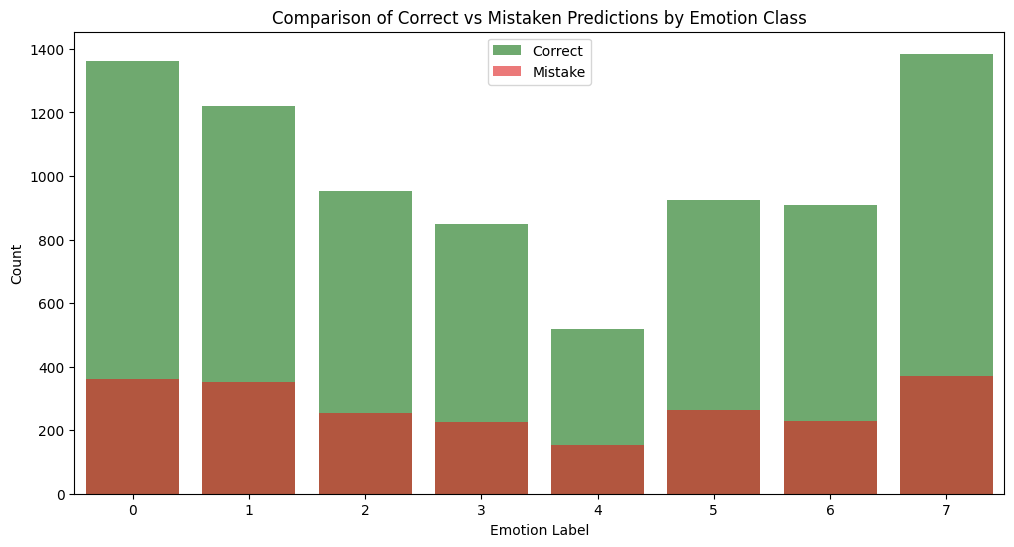

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

true_counts = df_true['multiClassLabel'].value_counts().sort_index()
mistake_counts = df_mistake['multiClassLabel'].value_counts().sort_index()

plt.figure(figsize=(12, 6))
sns.barplot(x=true_counts.index, y=true_counts.values, color='green', alpha=0.6, label='Correct')
sns.barplot(x=mistake_counts.index, y=mistake_counts.values, color='red', alpha=0.6, label='Mistake')
plt.xlabel("Emotion Label")
plt.ylabel("Count")
plt.title("Comparison of Correct vs Mistaken Predictions by Emotion Class")
plt.legend()
plt.show()


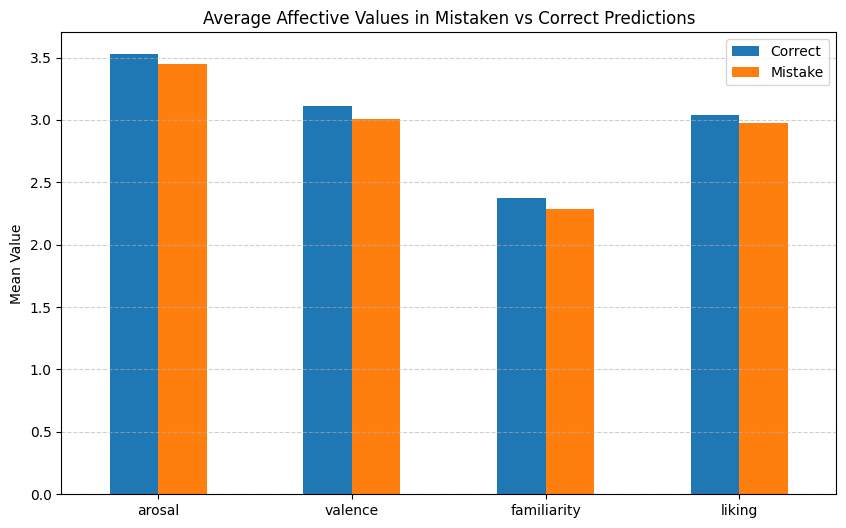

In [68]:
mistake_means = df_mistake[features].mean()
true_means = df_true[features].mean()

compare_df = pd.DataFrame({'Correct': true_means, 'Mistake': mistake_means})

compare_df.plot(kind='bar', figsize=(10, 6), title='Average Affective Values in Mistaken vs Correct Predictions')
plt.ylabel("Mean Value")
plt.xticks(rotation=0)
plt.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.show()


C:\Users\rajab\AppData\Local\Temp\ipykernel_3680\337552106.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  error_rate = df_result.groupby('arosal_bin').apply(lambda x: (x['predicted'] != x['true']).mean())
C:\Users\rajab\AppData\Local\Temp\ipykernel_3680\337552106.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  error_rate = df_result.groupby('arosal_bin').apply(lambda x: (x['predicted'] != x['true']).mean())


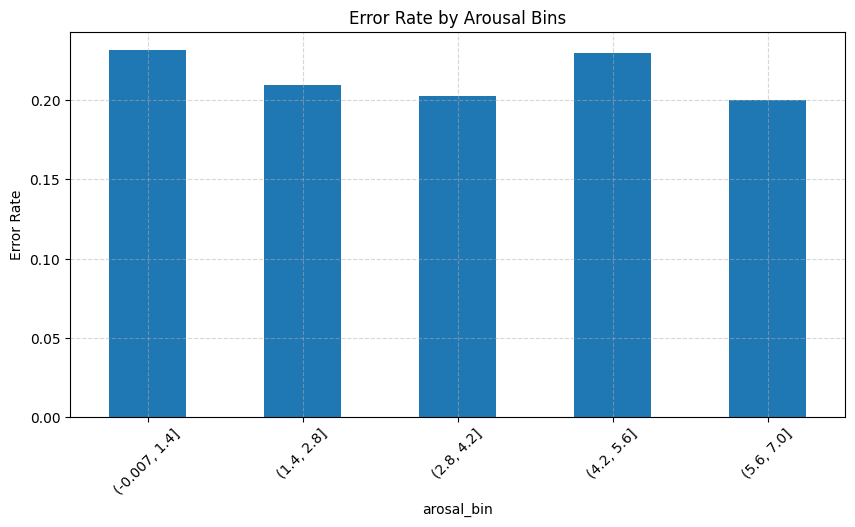

In [ ]:

df_result['arosal_bin'] = pd.cut(df_result['arosal'], bins=5)


error_rate = df_result.groupby('arosal_bin').apply(lambda x: (x['predicted'] != x['true']).mean())


error_rate.plot(kind='bar', figsize=(10, 5), title='Error Rate by Arousal Bins')
plt.ylabel("Error Rate")
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.show()


C:\Users\rajab\AppData\Local\Temp\ipykernel_3680\623096408.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  error_rate = df_result.groupby('valence_bin').apply(lambda x: (x['predicted'] != x['true']).mean())
C:\Users\rajab\AppData\Local\Temp\ipykernel_3680\623096408.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  error_rate = df_result.groupby('valence_bin').apply(lambda x: (x['predicted'] != x['true']).mean())


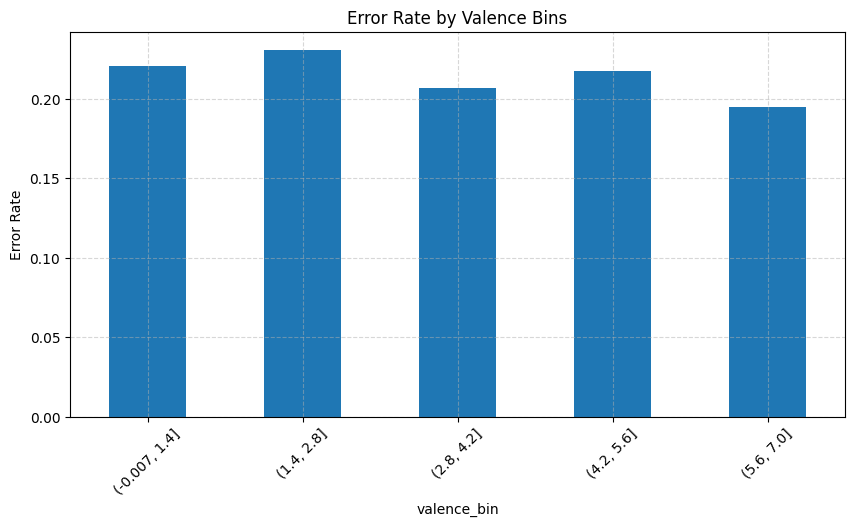

In [ ]:

df_result['valence_bin'] = pd.cut(df_result['valence'], bins=5)


error_rate = df_result.groupby('valence_bin').apply(lambda x: (x['predicted'] != x['true']).mean())


error_rate.plot(kind='bar', figsize=(10, 5), title='Error Rate by Valence Bins')
plt.ylabel("Error Rate")
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.show()


C:\Users\rajab\AppData\Local\Temp\ipykernel_3680\1230442393.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  error_rate = df_result.groupby('familiarity_bin').apply(lambda x: (x['predicted'] != x['true']).mean())
C:\Users\rajab\AppData\Local\Temp\ipykernel_3680\1230442393.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  error_rate = df_result.groupby('familiarity_bin').apply(lambda x: (x['predicted'] != x['true']).mean())


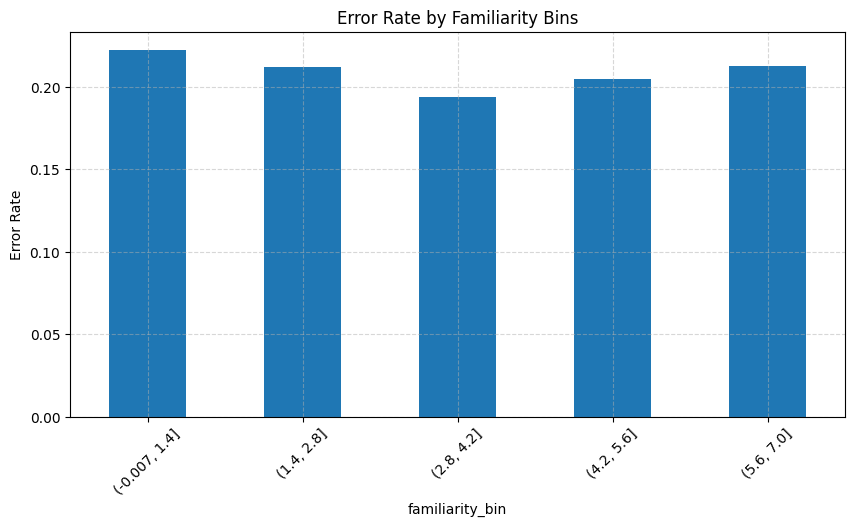

In [ ]:

df_result['familiarity_bin'] = pd.cut(df_result['familiarity'], bins=5)


error_rate = df_result.groupby('familiarity_bin').apply(lambda x: (x['predicted'] != x['true']).mean())


error_rate.plot(kind='bar', figsize=(10, 5), title='Error Rate by Familiarity Bins')
plt.ylabel("Error Rate")
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.show()


C:\Users\rajab\AppData\Local\Temp\ipykernel_3680\2493322615.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  error_rate = df_result.groupby('liking_bin').apply(lambda x: (x['predicted'] != x['true']).mean())
C:\Users\rajab\AppData\Local\Temp\ipykernel_3680\2493322615.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  error_rate = df_result.groupby('liking_bin').apply(lambda x: (x['predicted'] != x['true']).mean())


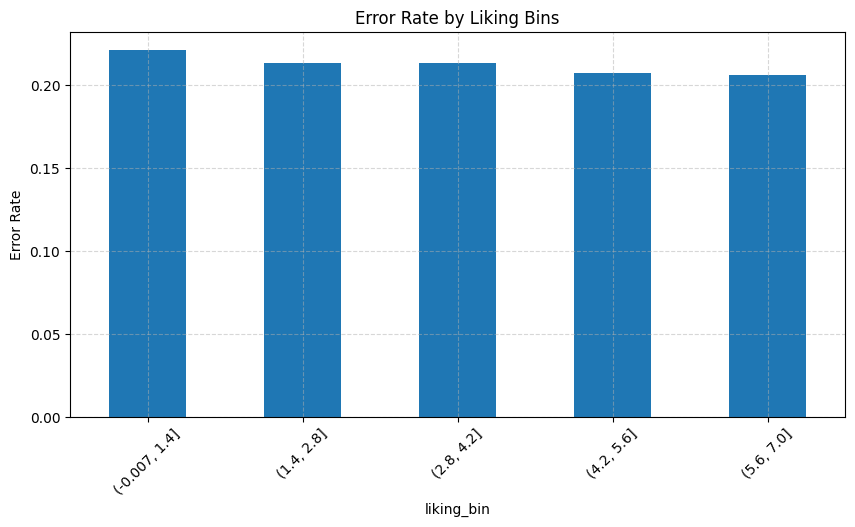

In [ ]:

df_result['liking_bin'] = pd.cut(df_result['liking'], bins=5)


error_rate = df_result.groupby('liking_bin').apply(lambda x: (x['predicted'] != x['true']).mean())


error_rate.plot(kind='bar', figsize=(10, 5), title='Error Rate by Liking Bins')
plt.ylabel("Error Rate")
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.show()


In [84]:
cases = []
for i in range(len(multi_class_labels)):
    resultCase = {
		"predicted": preds[i],
		"true": y_all[i],
		"multiClassLabel": multi_class_labels[i],
        "multi_class_labels_with_features":multi_class_labels_with_features[i],
        "arosal":arosals[i],
        "valence":valences[i],
        "familiarity":familiarities[i],
        "liking":likings[i]
	}
    cases.append(resultCase)

df_result_new = pd.DataFrame(cases)

In [85]:
df_mistake_new = df_result_new[df_result_new["predicted"] != df_result_new["true"]]
df_true_new = df_result_new[df_result_new["predicted"] == df_result_new["true"]]

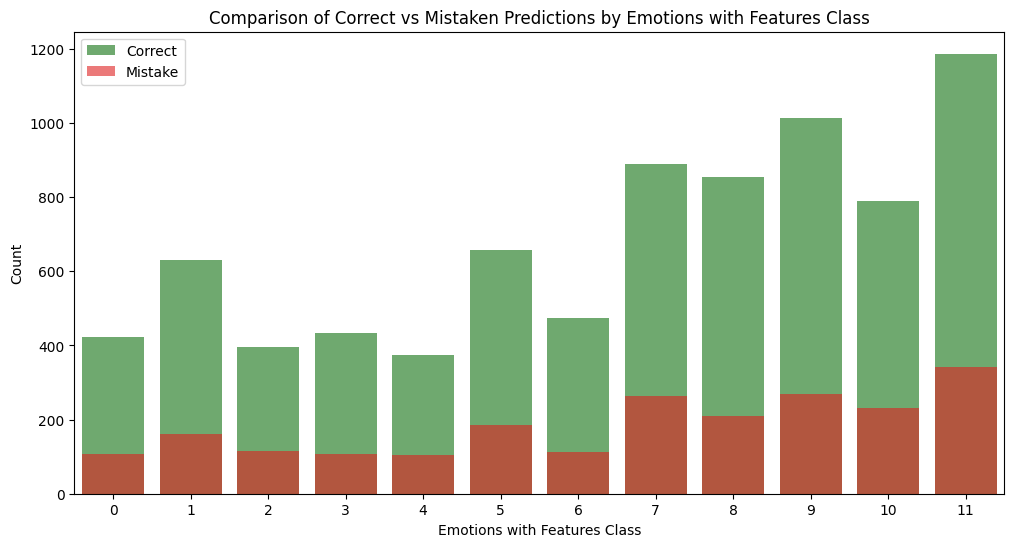

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


true_counts = df_true_new['multi_class_labels_with_features'].value_counts().sort_index()

mistake_counts = df_mistake_new['multi_class_labels_with_features'].value_counts().sort_index()

plt.figure(figsize=(12, 6))
sns.barplot(x=true_counts.index, y=true_counts.values, color='green', alpha=0.6, label='Correct')
sns.barplot(x=mistake_counts.index, y=mistake_counts.values, color='red', alpha=0.6, label='Mistake')
plt.xlabel("Emotions with Features Class")
plt.ylabel("Count")
plt.title("Comparison of Correct vs Mistaken Predictions by Emotions with Features Class")
plt.legend()
plt.show()


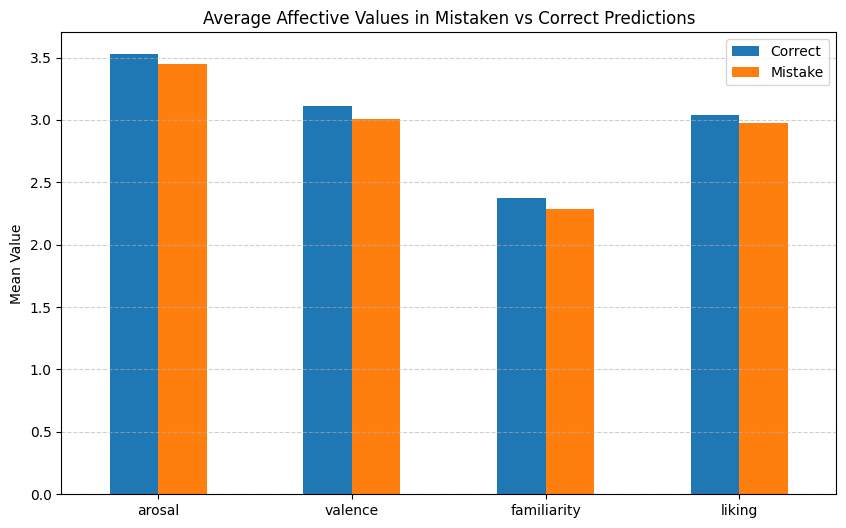

In [ ]:
mistake_means = df_mistake[features].mean()
true_means = df_true[features].mean()

compare_df = pd.DataFrame({'Correct': true_means, 'Mistake': mistake_means})

compare_df.plot(kind='bar', figsize=(10, 6), title='Average Affective Values in Mistaken vs Correct Predictions')
plt.ylabel("Mean Value")
plt.xticks(rotation=0)
plt.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.show()


C:\Users\rajab\AppData\Local\Temp\ipykernel_3680\337552106.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  error_rate = df_result.groupby('arosal_bin').apply(lambda x: (x['predicted'] != x['true']).mean())
C:\Users\rajab\AppData\Local\Temp\ipykernel_3680\337552106.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  error_rate = df_result.groupby('arosal_bin').apply(lambda x: (x['predicted'] != x['true']).mean())


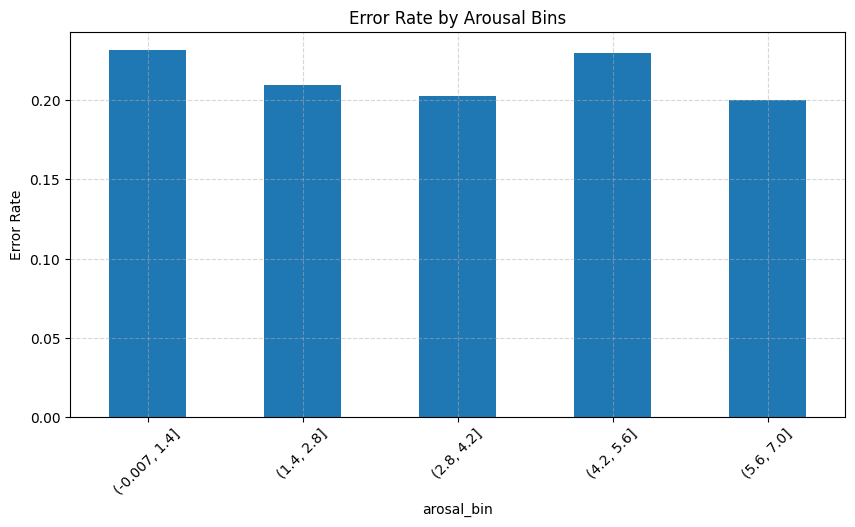

In [ ]:

df_result['arosal_bin'] = pd.cut(df_result['arosal'], bins=5)


error_rate = df_result.groupby('arosal_bin').apply(lambda x: (x['predicted'] != x['true']).mean())


error_rate.plot(kind='bar', figsize=(10, 5), title='Error Rate by Arousal Bins')
plt.ylabel("Error Rate")
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.show()


C:\Users\rajab\AppData\Local\Temp\ipykernel_3680\623096408.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  error_rate = df_result.groupby('valence_bin').apply(lambda x: (x['predicted'] != x['true']).mean())
C:\Users\rajab\AppData\Local\Temp\ipykernel_3680\623096408.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  error_rate = df_result.groupby('valence_bin').apply(lambda x: (x['predicted'] != x['true']).mean())


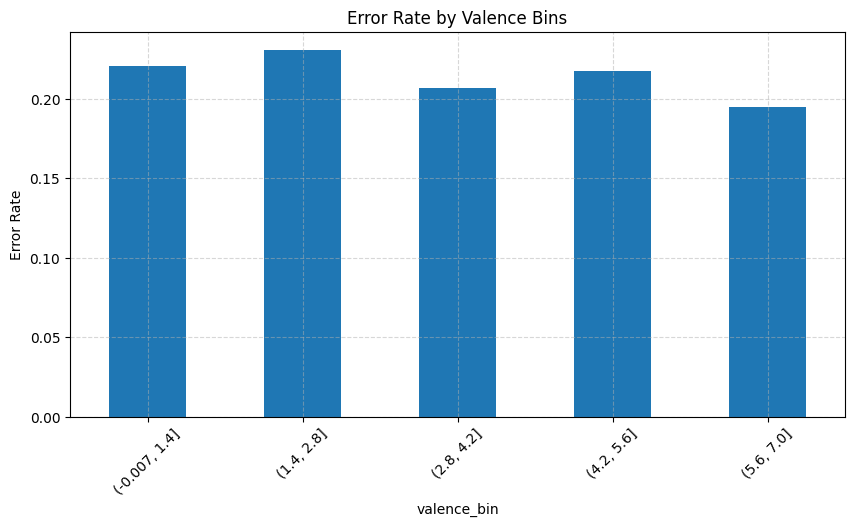

In [ ]:

df_result['valence_bin'] = pd.cut(df_result['valence'], bins=5)


error_rate = df_result.groupby('valence_bin').apply(lambda x: (x['predicted'] != x['true']).mean())


error_rate.plot(kind='bar', figsize=(10, 5), title='Error Rate by Valence Bins')
plt.ylabel("Error Rate")
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.show()


C:\Users\rajab\AppData\Local\Temp\ipykernel_3680\1230442393.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  error_rate = df_result.groupby('familiarity_bin').apply(lambda x: (x['predicted'] != x['true']).mean())
C:\Users\rajab\AppData\Local\Temp\ipykernel_3680\1230442393.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  error_rate = df_result.groupby('familiarity_bin').apply(lambda x: (x['predicted'] != x['true']).mean())


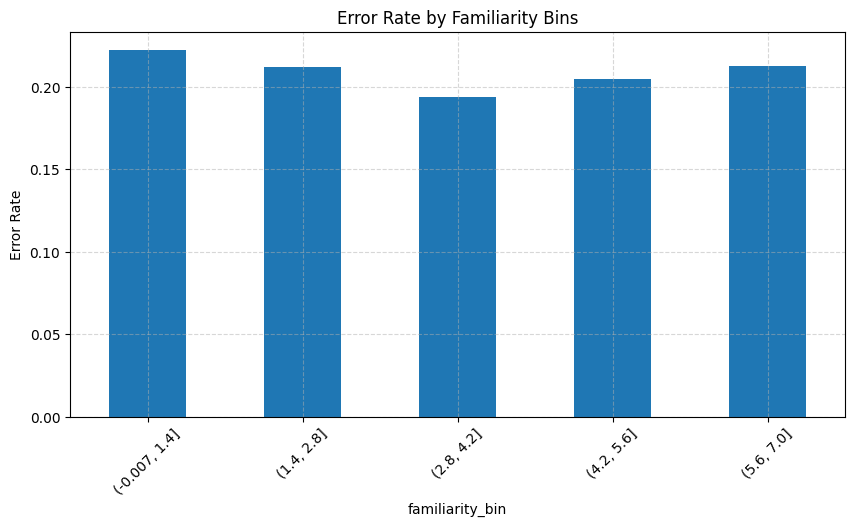

In [ ]:

df_result['familiarity_bin'] = pd.cut(df_result['familiarity'], bins=5)


error_rate = df_result.groupby('familiarity_bin').apply(lambda x: (x['predicted'] != x['true']).mean())


error_rate.plot(kind='bar', figsize=(10, 5), title='Error Rate by Familiarity Bins')
plt.ylabel("Error Rate")
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.show()


C:\Users\rajab\AppData\Local\Temp\ipykernel_3680\2493322615.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  error_rate = df_result.groupby('liking_bin').apply(lambda x: (x['predicted'] != x['true']).mean())
C:\Users\rajab\AppData\Local\Temp\ipykernel_3680\2493322615.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  error_rate = df_result.groupby('liking_bin').apply(lambda x: (x['predicted'] != x['true']).mean())


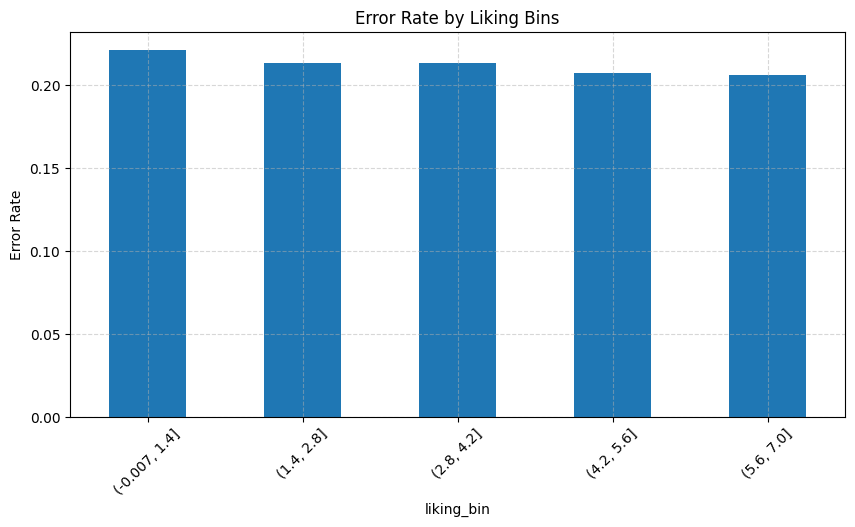

In [ ]:

df_result['liking_bin'] = pd.cut(df_result['liking'], bins=5)


error_rate = df_result.groupby('liking_bin').apply(lambda x: (x['predicted'] != x['true']).mean())


error_rate.plot(kind='bar', figsize=(10, 5), title='Error Rate by Liking Bins')
plt.ylabel("Error Rate")
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.show()
